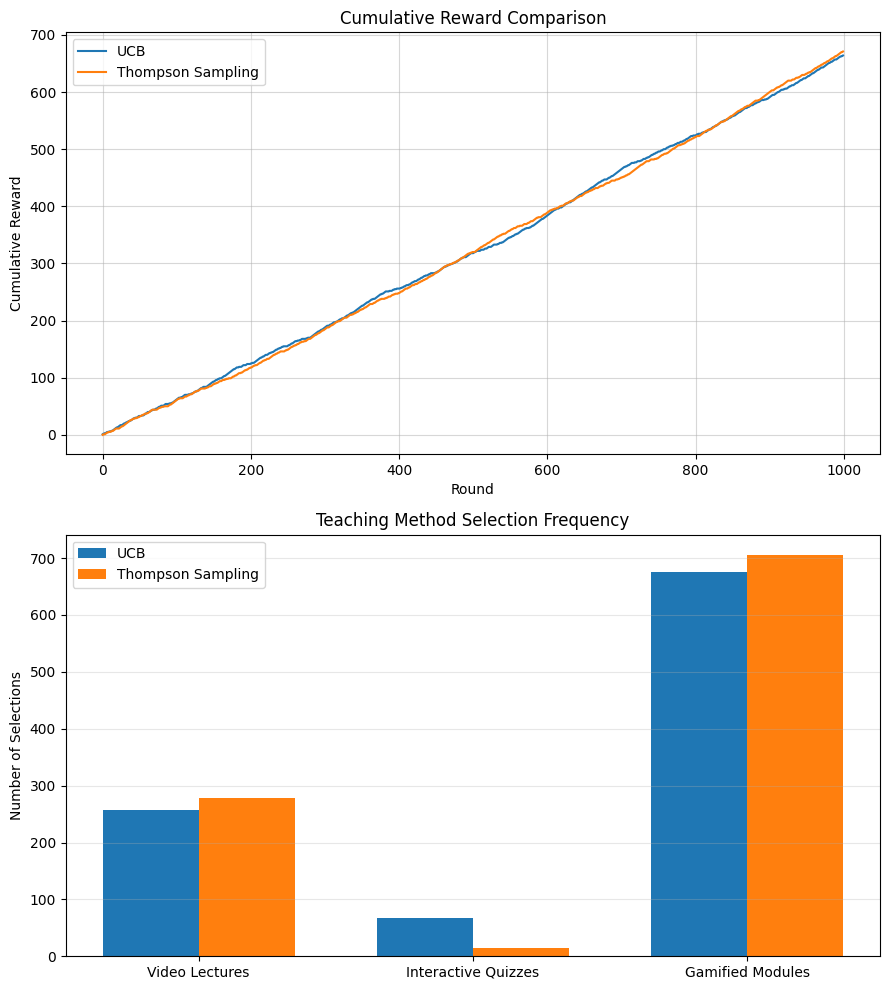

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# ENVIRONMENT SETUP
# ============================================================
np.random.seed(42)

arms = ["Video Lectures", "Interactive Quizzes", "Gamified Modules"]
probabilities = [0.6, 0.4, 0.7]
n_arms = len(arms)
rounds = 1000

# ============================================================
# UCB ALGORITHM
# ============================================================
counts_ucb = np.zeros(n_arms)
values_ucb = np.zeros(n_arms)
cumulative_rewards_ucb = []
total_reward_ucb = 0

for t in range(rounds):
    if t < n_arms:
        action = t
    else:
        confidence = np.sqrt((2 * np.log(t + 1)) / counts_ucb)
        ucb = values_ucb + confidence
        action = np.argmax(ucb)

    reward = np.random.binomial(1, probabilities[action])
    counts_ucb[action] += 1
    values_ucb[action] += (reward - values_ucb[action]) / counts_ucb[action]
    total_reward_ucb += reward
    cumulative_rewards_ucb.append(total_reward_ucb)

# ============================================================
# THOMPSON SAMPLING ALGORITHM
# ============================================================
alpha = np.ones(n_arms)
beta = np.ones(n_arms)
counts_ts = np.zeros(n_arms)
cumulative_rewards_ts = []
total_reward_ts = 0

for t in range(rounds):
    samples = np.random.beta(alpha, beta)
    action = np.argmax(samples)

    reward = np.random.binomial(1, probabilities[action])
    counts_ts[action] += 1
    if reward == 1:
        alpha[action] += 1
    else:
        beta[action] += 1

    total_reward_ts += reward
    cumulative_rewards_ts.append(total_reward_ts)

# ============================================================
# PLOTTING BOTH CHARTS (As shown in your screenshot)
# ============================================================
# Create a figure with 2 subplots stacked vertically
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 10))

# --- Plot 1: Cumulative Reward Line Chart ---
ax1.plot(cumulative_rewards_ucb, label="UCB", color="#1f77b4")
ax1.plot(cumulative_rewards_ts, label="Thompson Sampling", color="#ff7f0e")
ax1.set_xlabel("Round")
ax1.set_ylabel("Cumulative Reward")
ax1.set_title("Cumulative Reward Comparison")
ax1.legend()
ax1.grid(True, linestyle="-", alpha=0.5)

# --- Plot 2: Selection Frequency Bar Chart ---
x = np.arange(n_arms)  # Label locations
width = 0.35           # Width of the bars

# Draw side-by-side bars
ax2.bar(x - width/2, counts_ucb, width, label="UCB", color="#1f77b4")
ax2.bar(x + width/2, counts_ts, width, label="Thompson Sampling", color="#ff7f0e")

ax2.set_ylabel("Number of Selections")
print("\n")
ax2.set_title("Teaching Method Selection Frequency")
ax2.set_xticks(x)
ax2.set_xticklabels(arms)
ax2.legend()
ax2.grid(True, linestyle="-", alpha=0.3, axis="y")

# Adjust layout and render
plt.tight_layout()
plt.show()
